# Figure S7

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import load_ddm_posterior, load_ddm_rhat, load_ddm_ess, DATASET_LABELS
import numpy as np
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

MODELS = {
    "stpxch":    "HDDM_Base_Lag1-stp_Pupil_stp",
    "driftxch":  "HDDM_Base_Lag1-drift_Pupil_drift",
    "valuation": "HDDM_Base_Pupil_valuation",
    "boundary":  "HDDM_Base_Pupil_boundary",
    "ndt":       "HDDM_Base_Pupil_ndt",
}

# Display name per model, used in the x-label instead of the raw model_id.
MODEL_NAMES = {
    "stpxch":    "SP-CH x Pupil",
    "driftxch":  "Drift-CH x Pupil",
    "valuation": "Valuation x Pupil",
    "boundary":  "Boundary x Pupil",
    "ndt":       "NDT x Pupil",
}

# Rhat/ESS per (model, variable), one CSV per dataset -- same source/method
# as results/analysis_ddm/hddm_compare/checking_ddm_stats.ipynb.
RHAT_BY_DATASET = {ds: load_ddm_rhat(ds) for ds in DATASETS}
ESS_BY_DATASET = {ds: load_ddm_ess(ds) for ds in DATASETS}

### Helper functions

In [2]:
import string


def summarize_posterior(model_id, dataset, param):
    """Flatten the 4 chains into one pooled sample, then the 95% CI as the
    2.5th/97.5th percentiles."""
    posterior = load_ddm_posterior(model_id, dataset)
    samples = posterior[param].flatten()
    lo, hi = np.percentile(samples, [2.5, 97.5])
    return samples, np.median(samples), lo, hi


def ln_bf_sign(samples):
    """ln Bayes Factor for the parameter being >0 vs. <0, from the
    (continuity-corrected) proportion of posterior mass on each side --
    equal to the posterior odds under a prior symmetric about zero."""
    n = len(samples)
    eps = 1 / (2 * n)
    p_pos = np.clip(np.mean(samples > 0), eps, 1 - eps)
    return np.log(p_pos / (1 - p_pos))


def get_convergence(model_id, dataset, param):
    """Group-level Rhat/ESS for one parameter, from the same rhat/ess CSVs
    used in results/analysis_ddm/hddm_compare/checking_ddm_stats.ipynb."""
    rhat_df = RHAT_BY_DATASET[dataset]
    ess_df = ESS_BY_DATASET[dataset]
    rhat = rhat_df.loc[(rhat_df["model"] == model_id) & (rhat_df["variable"] == param), "rhat"].iloc[0]
    ess = ess_df.loc[(ess_df["model"] == model_id) & (ess_df["variable"] == param), "ess"].iloc[0]
    return rhat, ess


def plot_param_hist(ax, model_id, dataset, param, color):
    """Histogram of the pooled posterior in the given (per-parameter) color,
    annotated with the directional Bayes Factor and convergence diagnostics."""
    samples, median, lo, hi = summarize_posterior(model_id, dataset, param)
    ax.hist(samples, bins=40, color=color, alpha=0.5)
    ax.hist(samples, bins=40, color="black", histtype="step")
    ax.axvline(0, color="black", linestyle="--", linewidth=2, zorder=1)
    ax.set_xlim(-0.15, 0.15)
    lnbf = ln_bf_sign(samples)
    rhat, ess = get_convergence(model_id, dataset, param)
    ax.text(0.05, 0.95,
            f"ln(BF(>0,<0))={lnbf:.3f}\nR_hat={rhat:.3f}\nESS={ess:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=12)


def build_row_labels(flat_params):
    """A./B./C./... one label per distinct model_key, placed on that
    model's first row (a model spanning multiple rows gets a single
    label). Restarts from A for whichever flat_params list is passed in."""
    labels = [None] * len(flat_params)
    letters = iter(string.ascii_uppercase)
    prev_model_key = None
    for i, (model_key, _, _) in enumerate(flat_params):
        if model_key != prev_model_key:
            labels[i] = f"{next(letters)}."
            prev_model_key = model_key
    return labels


def plot_param_grid(flat_params, param_colors, save_path):
    """One combined figure: one row per (model_key, param, description)
    entry, one column per dataset, with A./B./C./... row labels."""
    row_labels = build_row_labels(flat_params)
    fig, axes = plt.subplots(nrows=len(flat_params), ncols=3, figsize=(15, 4 * len(flat_params)), squeeze=False)

    for row, (model_key, param, description) in enumerate(flat_params):
        model_id = MODELS[model_key]
        model_name = MODEL_NAMES[model_key]
        color = param_colors[param]

        for col, dataset in enumerate(DATASETS):
            ax = axes[row, col]
            plot_param_hist(ax, model_id, dataset, param, color)

            if row == 0:
                ax.set_title(DATASET_LABELS.get(dataset, dataset))

            if col == 1:
                ax.set_xlabel(f"Interaction of pupil with {description} in model {model_name}")

        if row_labels[row]:
            axes[row, 0].text(-0.25, 1.1, row_labels[row], transform=axes[row, 0].transAxes,
                              fontsize=26, fontweight="bold", va="top", ha="right")

    plt.tight_layout()
    fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

### Figure S7
Two figures: (1) starting-point x pupil and drift x pupil (A, B); (2) valuation x pupil -- gain then loss below it -- boundary x pupil, and non-decision time x pupil (relabeled A, B, C). One row per parameter, one column per dataset. Each row has its own fixed color; each panel is the pooled posterior histogram for that parameter, annotated with the directional Bayes Factor (posterior odds of >0 vs. <0) and convergence diagnostics (Rhat, ESS).

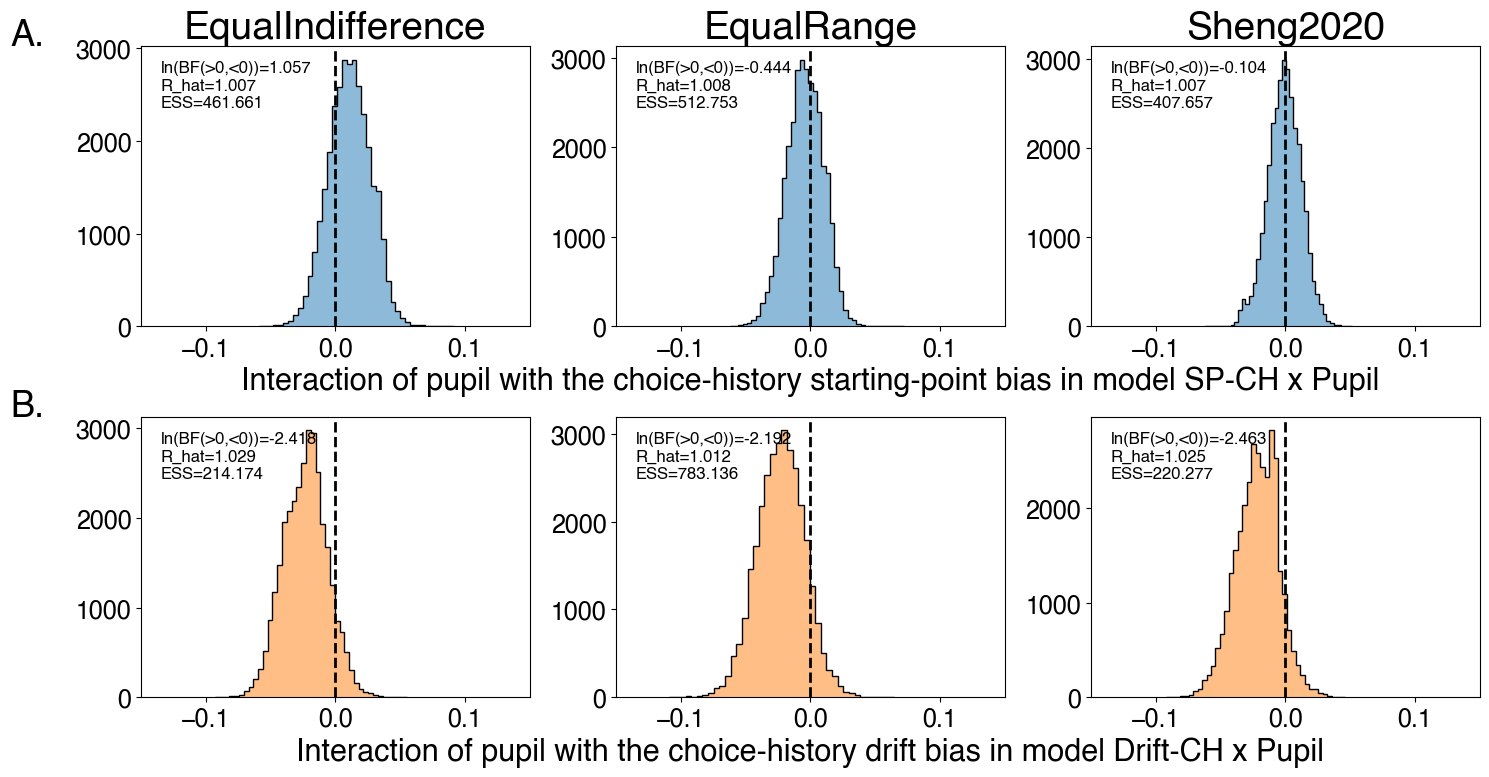

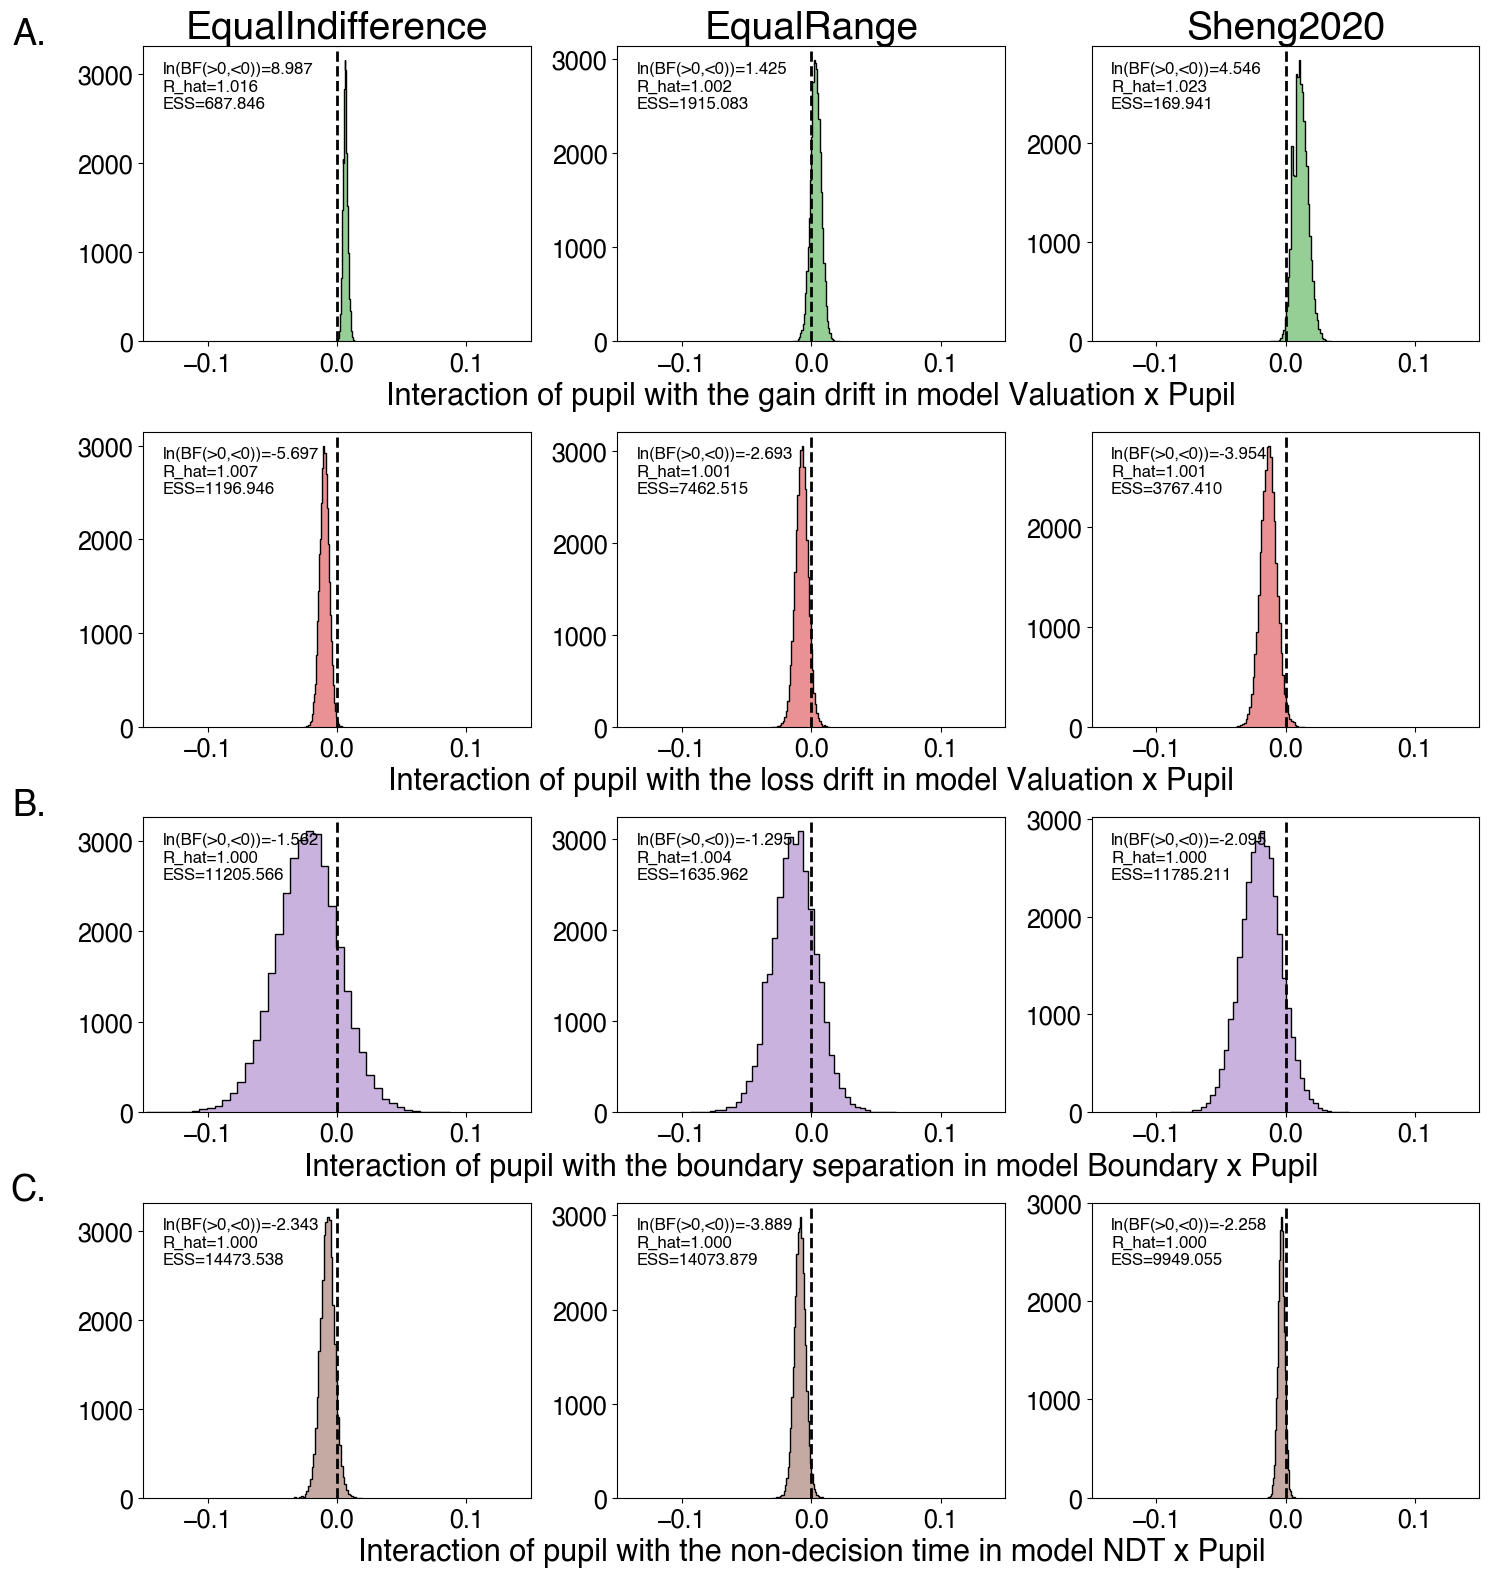

In [3]:
# (model_key, param, description) -- one entry per row, in plotting order.
PANEL_AB_PARAMS = [
    ("stpxch",   "z_choice_prev1:pupil", "the choice-history starting-point bias"),
    ("driftxch", "v_choice_prev1:pupil", "the choice-history drift bias"),
]

PANEL_CDE_PARAMS = [
    ("valuation", "v_gain_centered:pupil", "the gain drift"),
    ("valuation", "v_loss_centered:pupil", "the loss drift"),
    ("boundary",  "a_pupil",               "the boundary separation"),
    ("ndt",       "t_pupil",               "the non-decision time"),
]

# One color per parameter, shared across both figures.
PARAM_COLORS = {
    "z_choice_prev1:pupil":  "#1f77b4",
    "v_choice_prev1:pupil":  "#ff7f0e",
    "v_gain_centered:pupil": "#2ca02c",
    "v_loss_centered:pupil": "#d62728",
    "a_pupil":               "#9467bd",
    "t_pupil":               "#8c564b",
}

plot_param_grid(PANEL_AB_PARAMS, PARAM_COLORS, "saved/figureS7_1.svg")
plot_param_grid(PANEL_CDE_PARAMS, PARAM_COLORS, "saved/figureS7_2.svg")